STUDENT  PERFORMANCE ANALYSIS

## Step 1: Install Required Packages in Google Colab

In [ ]:


!pip install -q pandas numpy matplotlib seaborn scipy scikit-learn tensorflow

print("All required libraries installed successfully!")


All required libraries installed successfully!


## Step 2: Download the Official UCI Student Performance Dataset Automatically

In [ ]:

# STEP 2: Dataset Acquisition and Loading

import os
import urllib.request
import zipfile
import io
import pandas as pd
import numpy as np

# Create required project folders
os.makedirs("dataset", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("outputs/charts", exist_ok=True)
os.makedirs("outputs/results", exist_ok=True)

dataset_path = "dataset/student-mat.csv"

# Download dataset only if it is not already available
if not os.path.exists(dataset_path):

    UCI_URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

    print("Downloading official UCI dataset...")

    request = urllib.request.Request(
        UCI_URL,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request, timeout=30) as response:
        outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))

        for name in outer_zip.namelist():
            if name.endswith("student-mat.csv"):
                with open(dataset_path, "wb") as f:
                    f.write(outer_zip.read(name))
                break

            elif name.endswith("student.zip"):
                inner_zip = zipfile.ZipFile(
                    io.BytesIO(outer_zip.read(name))
                )

                for inner_name in inner_zip.namelist():
                    if inner_name.endswith("student-mat.csv"):
                        with open(dataset_path, "wb") as f:
                            f.write(inner_zip.read(inner_name))
                        break

# Load dataset
df = pd.read_csv(dataset_path, sep=";")

print("Dataset loaded successfully!")
print("Number of records:", df.shape[0])
print("Number of attributes:", df.shape[1])

display(df.head())

print("\nDataset Information:")
df.info()


Dataset loaded successfully!
Number of records: 395
Number of attributes: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    

## Step 3: Complete Data Preprocessing & Leakage Prevention
- Check missing values and duplicate records
- IQR Outlier Detection: $IQR = Q_3 - Q_1$
- 70% Train, 15% Validation, 15% Test split (`random_state=42`)
- Scalers and One-Hot Encoders fitted strictly on training data

In [ ]:

# STEP 3: Data Preprocessing and Data Splitting

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import pickle

# 1. Missing value analysis
print("Missing values:", df.isnull().sum().sum())

# 2. Duplicate analysis
print("Duplicate rows:", df.duplicated().sum())

# 3. Separate features and target
X = df.drop(columns=["G3"])
y = df["G3"]

# 4. Split into training, validation and testing sets
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("\nDataset Split:")
print("Training records:", len(X_train_raw))
print("Validation records:", len(X_val_raw))
print("Testing records:", len(X_test_raw))

# 5. Identify numerical and categorical columns
num_cols = X_train_raw.select_dtypes(
    include=["number"]
).columns.tolist()

cat_cols = X_train_raw.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))

# 6. Create preprocessing pipeline
ct = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(
        drop="first",
        sparse_output=False,
        handle_unknown="ignore"
    ), cat_cols)
])

# Fit only on training data
X_train_proc = ct.fit_transform(X_train_raw)

# Transform validation and testing data
X_val_proc = ct.transform(X_val_raw)
X_test_proc = ct.transform(X_test_raw)

print("\nPreprocessing completed!")
print("Processed feature count:", X_train_proc.shape[1])

# Save preprocessing pipeline
with open("models/preprocessing_pipeline.pkl", "wb") as f:
    pickle.dump(ct, f)


Missing values: 0
Duplicate rows: 0

Dataset Split:
Training records: 276
Validation records: 59
Testing records: 60

Numerical features: 15
Categorical features: 17

Preprocessing completed!
Processed feature count: 41


===== IQR OUTLIER ANALYSIS =====

Attribute: absences
Q1: 0.0
Q3: 8.0
IQR: 8.0
Lower Bound: -12.0
Upper Bound: 20.0
Outlier Count: 15

Attribute: failures
Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Outlier Count: 83


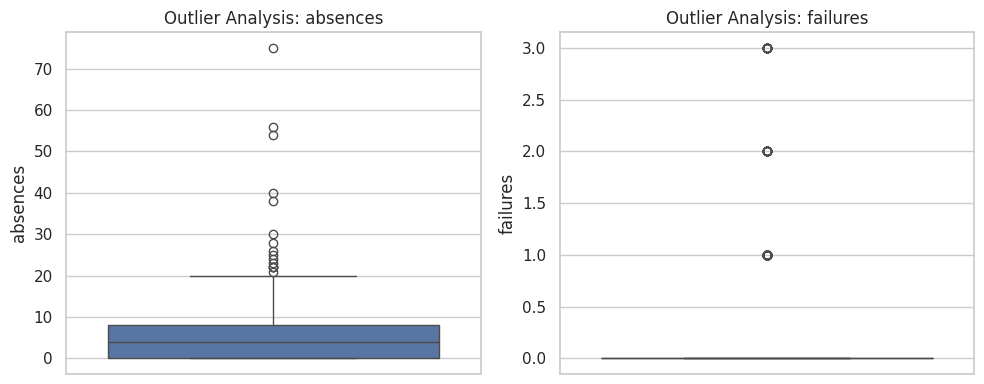


Valid extreme observations are retained.


In [ ]:

# STEP 3A: IQR Outlier Detection

import matplotlib.pyplot as plt
import seaborn as sns

outlier_columns = ["absences", "failures"]

print("===== IQR OUTLIER ANALYSIS =====")

for column in outlier_columns:

    Q1 = X_train_raw[column].quantile(0.25)
    Q3 = X_train_raw[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print("\nAttribute:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))

# Boxplot visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, column in zip(axes, outlier_columns):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title("Outlier Analysis: " + column)
    ax.set_ylabel(column)

plt.tight_layout()
plt.savefig("outputs/charts/iqr_outlier_analysis.png", dpi=200)
plt.show()

print("\nValid extreme observations are retained.")


## Step 4: Exploratory Data Analysis & Statistical Hypothesis Testing

In [ ]:

# STEP 4: Exploratory Data Analysis and Statistical Analysis

from scipy import stats

g3_series = df["G3"]

print("===== G3 DESCRIPTIVE STATISTICS =====")

print("Mean:", round(g3_series.mean(), 2))
print("Median:", round(g3_series.median(), 2))
print("Variance:", round(g3_series.var(), 2))
print("Standard Deviation:", round(g3_series.std(), 2))
print("Skewness:", round(g3_series.skew(), 3))
print("Kurtosis:", round(g3_series.kurtosis(), 3))

# Normality test
w, p = stats.shapiro(g3_series)

print("\n===== SHAPIRO-WILK NORMALITY TEST =====")
print("W Statistic:", round(w, 4))
print("P Value:", p)

if p < 0.05:
    print("Conclusion: G3 does not follow a normal distribution.")
else:
    print("Conclusion: Normality is not rejected.")

# ANOVA: Study time versus final grade
groups = [
    group["G3"].values
    for _, group in df.groupby("studytime")
]

f_stat, p_val = stats.f_oneway(*groups)

print("\n===== ONE-WAY ANOVA =====")
print("F Statistic:", round(f_stat, 3))
print("P Value:", p_val)

# Welch's t-test: Higher education aspiration
yes_g3 = df[df["higher"] == "yes"]["G3"]
no_g3 = df[df["higher"] == "no"]["G3"]

t_stat, t_p = stats.ttest_ind(
    yes_g3, no_g3, equal_var=False
)

print("\n===== WELCH'S T-TEST =====")
print("T Statistic:", round(t_stat, 3))
print("P Value:", t_p)
print("Higher education aspirants mean:", round(yes_g3.mean(), 2))
print("Non-aspirants mean:", round(no_g3.mean(), 2))

# Pearson correlation: Absences versus G3
corr, corr_p = stats.pearsonr(df["absences"], df["G3"])

print("\n===== ABSENCES CORRELATION =====")
print("Pearson Correlation:", round(corr, 3))
print("P Value:", round(corr_p, 4))


===== G3 DESCRIPTIVE STATISTICS =====
Mean: 10.42
Median: 11.0
Variance: 20.99
Standard Deviation: 4.58
Skewness: -0.733
Kurtosis: 0.403

===== SHAPIRO-WILK NORMALITY TEST =====
W Statistic: 0.9287
P Value: 8.835916843805374e-13
Conclusion: G3 does not follow a normal distribution.

===== ONE-WAY ANOVA =====
F Statistic: 1.728
P Value: 0.1607228096836598

===== WELCH'S T-TEST =====
T Statistic: 3.447
P Value: 0.002440033985581924
Higher education aspirants mean: 10.61
Non-aspirants mean: 6.8

===== ABSENCES CORRELATION =====
Pearson Correlation: 0.034
P Value: 0.4973


## Step 5: Generate and Display All 8 Required Visualizations
Each visualization fulfills the assignment rubric with Title, Axis Labels, Observations, and Conclusions.

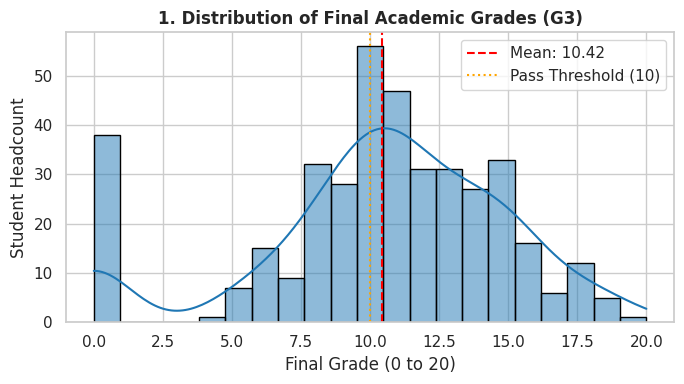

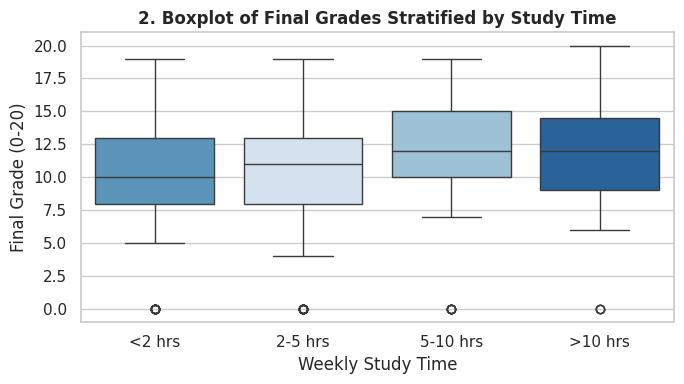

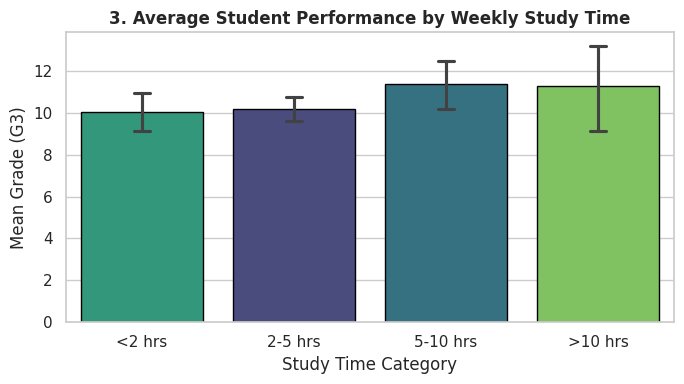

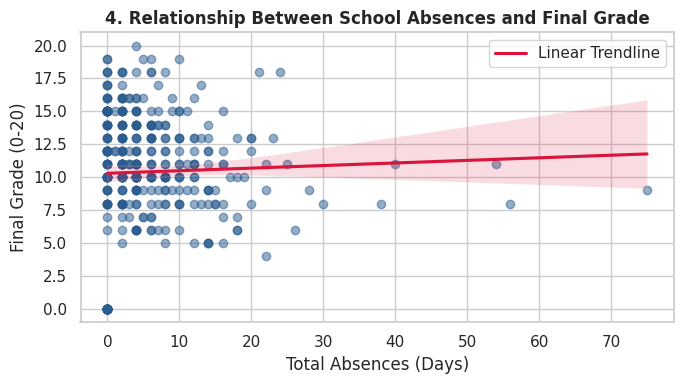

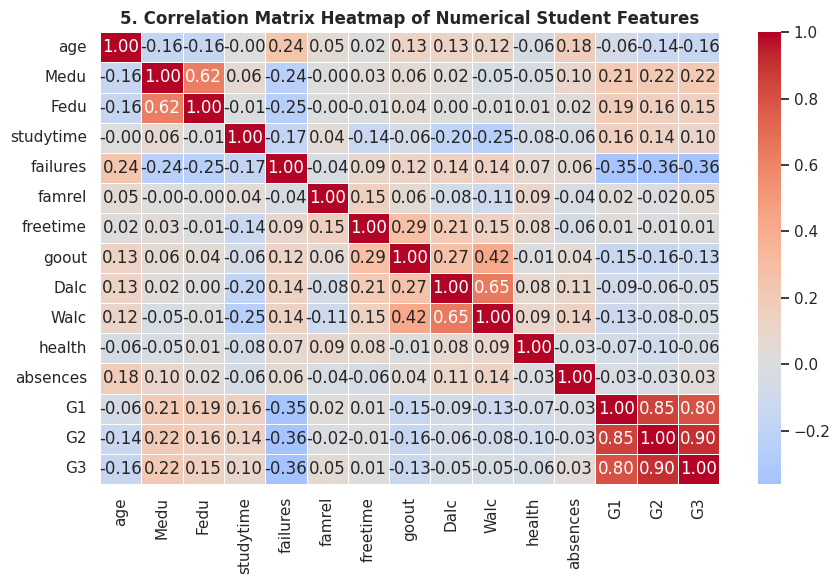

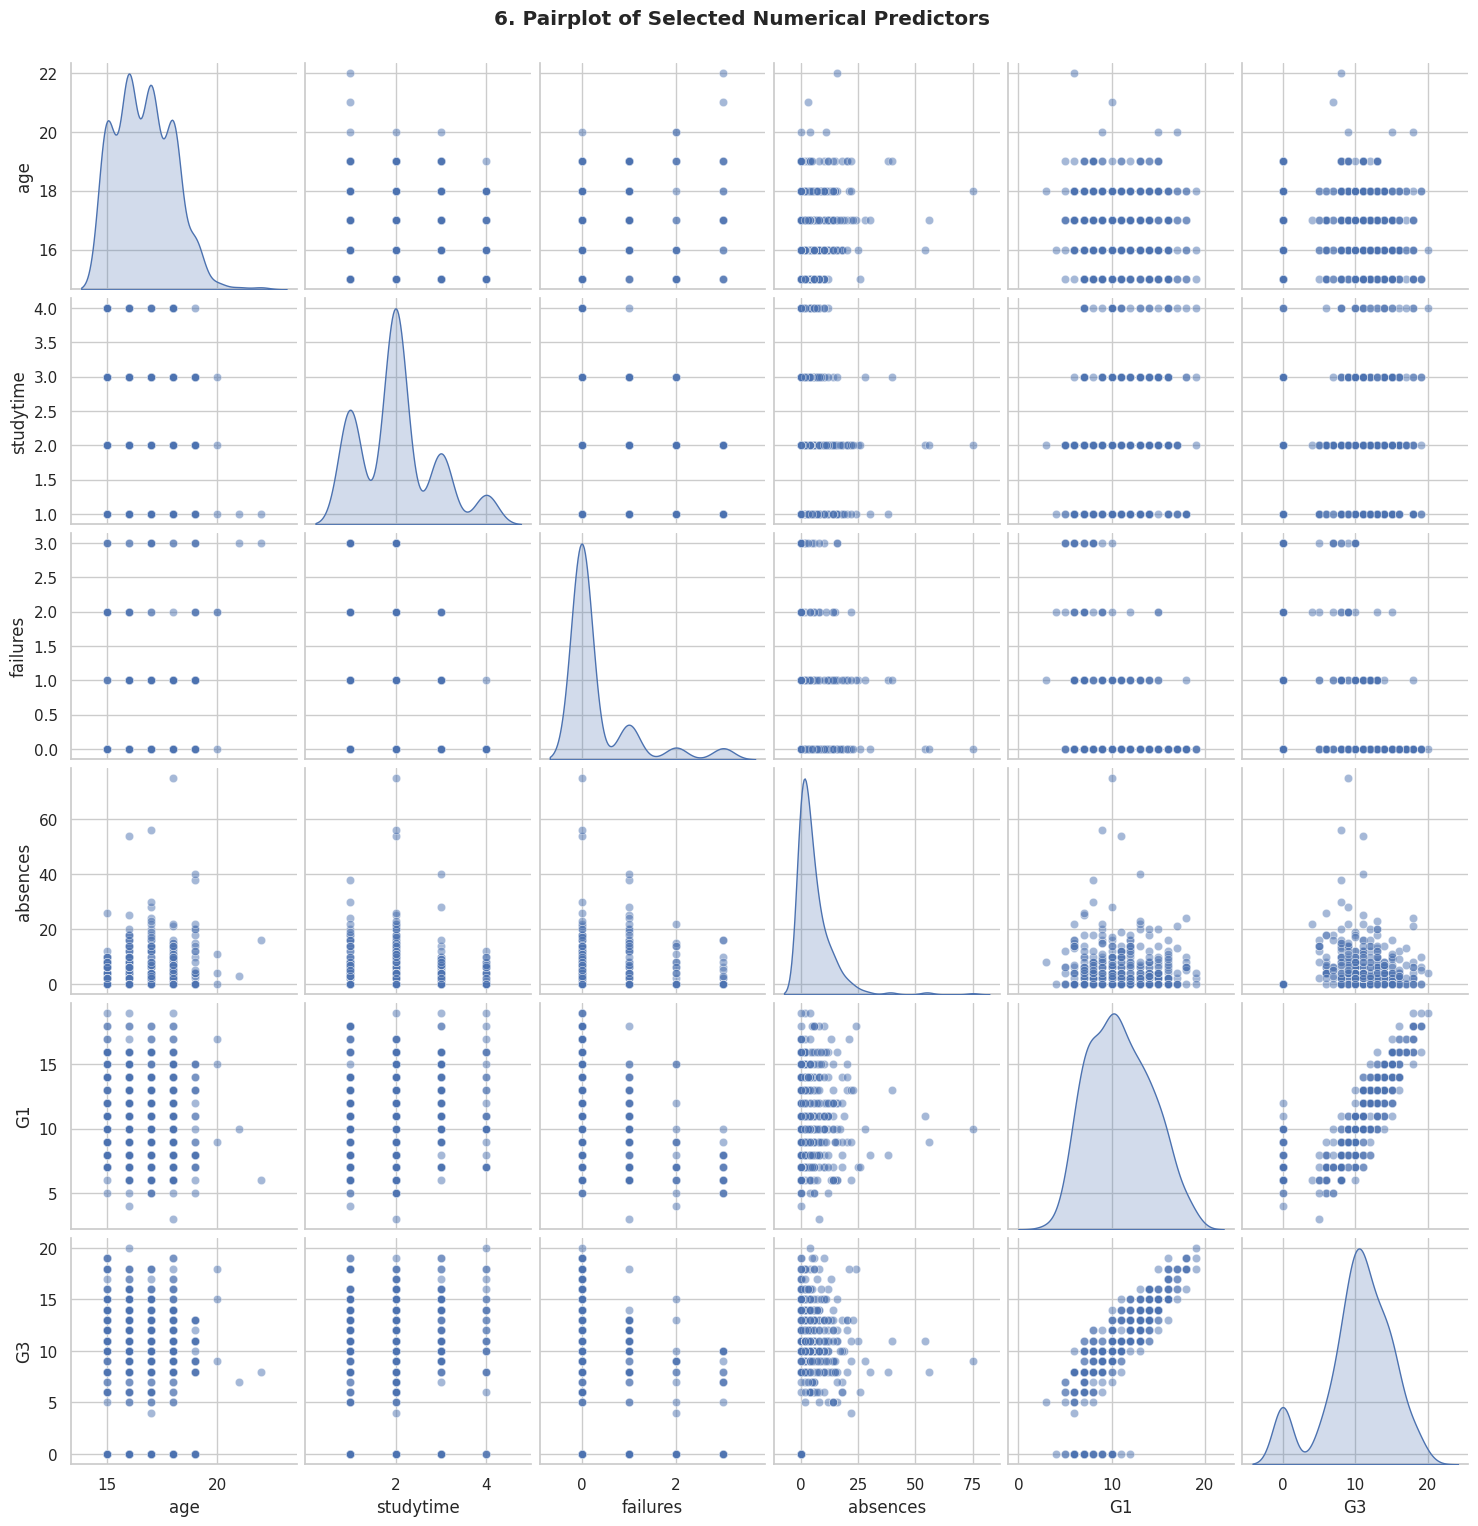

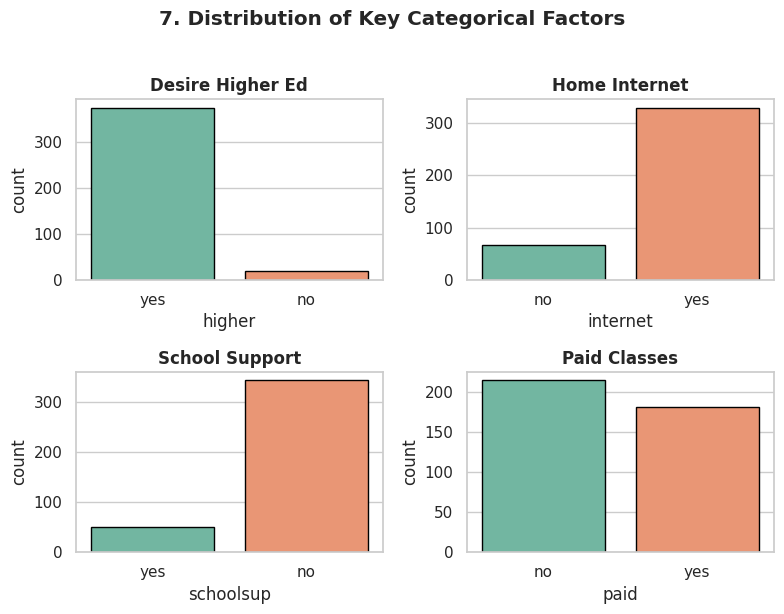

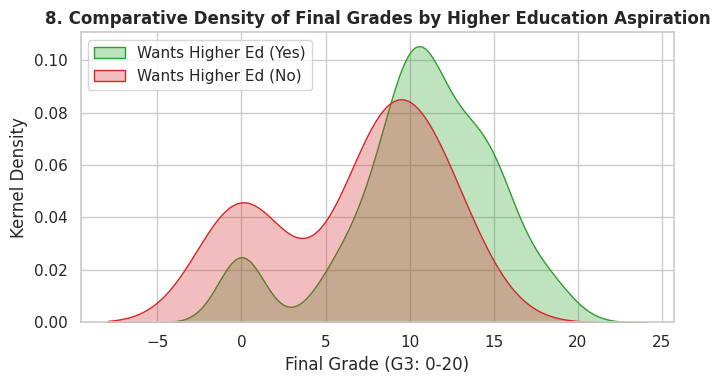

All 8 required visualizations generated and saved!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Histogram of G3
plt.figure(figsize=(7, 4))
sns.histplot(df['G3'], bins=21, kde=True, color='#1f77b4', edgecolor='black')
plt.axvline(df['G3'].mean(), color='red', linestyle='--', label=f"Mean: {df['G3'].mean():.2f}")
plt.axvline(10, color='orange', linestyle=':', label="Pass Threshold (10)")
plt.title("1. Distribution of Final Academic Grades (G3)", fontweight='bold')
plt.xlabel("Final Grade (0 to 20)")
plt.ylabel("Student Headcount")
plt.legend()
plt.tight_layout()
plt.savefig('outputs/charts/1_histogram_g3.png', dpi=200)
plt.show()

# 2. Boxplot across Study Time
plt.figure(figsize=(7, 4))
labels = {1: '<2 hrs', 2: '2-5 hrs', 3: '5-10 hrs', 4: '>10 hrs'}
df_temp = df.copy()
df_temp['study_lbl'] = df_temp['studytime'].map(labels)
sns.boxplot(data=df_temp, x='study_lbl', y='G3', order=['<2 hrs', '2-5 hrs', '5-10 hrs', '>10 hrs'], palette='Blues', hue='study_lbl', legend=False)
plt.title("2. Boxplot of Final Grades Stratified by Study Time", fontweight='bold')
plt.xlabel("Weekly Study Time")
plt.ylabel("Final Grade (0-20)")
plt.tight_layout()
plt.savefig('outputs/charts/2_boxplot_g3.png', dpi=200)
plt.show()

# 3. Bar Chart Study Time
plt.figure(figsize=(7, 4))
sns.barplot(data=df_temp, x='study_lbl', y='G3', order=['<2 hrs', '2-5 hrs', '5-10 hrs', '>10 hrs'], errorbar=('ci', 95), palette='viridis', hue='study_lbl', legend=False, capsize=0.1, edgecolor='black')
plt.title("3. Average Student Performance by Weekly Study Time", fontweight='bold')
plt.xlabel("Study Time Category")
plt.ylabel("Mean Grade (G3)")
plt.tight_layout()
plt.savefig('outputs/charts/3_barchart_studytime.png', dpi=200)
plt.show()

# 4. Scatterplot Absences vs G3
plt.figure(figsize=(7, 4))
sns.regplot(data=df, x='absences', y='G3', scatter_kws={'alpha': 0.5, 'color': '#2b5c8f'}, line_kws={'color': 'crimson', 'label': 'Linear Trendline'})
plt.title("4. Relationship Between School Absences and Final Grade", fontweight='bold')
plt.xlabel("Total Absences (Days)")
plt.ylabel("Final Grade (0-20)")
plt.legend()
plt.tight_layout()
plt.savefig('outputs/charts/4_scatterplot_absences.png', dpi=200)
plt.show()

# 5. Correlation Heatmap
plt.figure(figsize=(9, 6))
num_vars = ['age', 'Medu', 'Fedu', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
sns.heatmap(df[num_vars].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title("5. Correlation Matrix Heatmap of Numerical Student Features", fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/charts/5_correlation_heatmap.png', dpi=200)
plt.show()

# 6. Pairplot
pair_vars = ['age', 'studytime', 'failures', 'absences', 'G1', 'G3']
g = sns.pairplot(df[pair_vars], diag_kind='kde', plot_kws={'alpha': 0.5})
g.fig.suptitle("6. Pairplot of Selected Numerical Predictors", y=1.02, fontweight='bold')
g.savefig('outputs/charts/6_pairplot_numerical.png', dpi=200)
plt.show()

# 7. Categorical Factors Countplot
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
attrs = [('higher', 'Desire Higher Ed'), ('internet', 'Home Internet'), ('schoolsup', 'School Support'), ('paid', 'Paid Classes')]
for ax, (col, title) in zip(axes.flatten(), attrs):
    sns.countplot(data=df, x=col, hue=col, palette='Set2', legend=False, edgecolor='black', ax=ax)
    ax.set_title(title, fontweight='bold')
plt.suptitle("7. Distribution of Key Categorical Factors", y=1.02, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/charts/7_countplot_categorical.png', dpi=200)
plt.show()

# 8. Comparative Density
plt.figure(figsize=(7, 4))
sns.kdeplot(data=df[df['higher'] == 'yes']['G3'], label="Wants Higher Ed (Yes)", color='#2ca02c', fill=True, alpha=0.3)
sns.kdeplot(data=df[df['higher'] == 'no']['G3'], label="Wants Higher Ed (No)", color='#d62728', fill=True, alpha=0.3)
plt.title("8. Comparative Density of Final Grades by Higher Education Aspiration", fontweight='bold')
plt.xlabel("Final Grade (G3: 0-20)")
plt.ylabel("Kernel Density")
plt.legend()
plt.tight_layout()
plt.savefig('outputs/charts/8_distribution_comparison.png', dpi=200)
plt.show()

print("All 8 required visualizations generated and saved!")

## Step 6: Deep Learning Model (Multi-Layer Perceptron) Training
Architecture:
- Input: Processed feature dimension
- Hidden Layer 1: 128 neurons, ReLU, Dropout 0.2
- Hidden Layer 2: 64 neurons, ReLU, Dropout 0.2
- Hidden Layer 3: 32 neurons, ReLU
- Output: 1 neuron, Linear
- Optimizer: Adam, Loss: MSE, Metric: MAE, EarlyStopping & ModelCheckpoint

In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
import pandas as pd
import numpy as np
import os

tf.random.set_seed(42)
np.random.seed(42)

os.makedirs("models", exist_ok=True)

# Five configurations for hyperparameter tuning
configurations = [
    {"name": "Config 1", "units": [128, 64, 32], "lr": 0.001, "dropout": 0.2},
    {"name": "Config 2", "units": [64, 32, 16], "lr": 0.001, "dropout": 0.1},
    {"name": "Config 3", "units": [256, 128, 64], "lr": 0.0005, "dropout": 0.3},
    {"name": "Config 4", "units": [128, 64, 32], "lr": 0.0005, "dropout": 0.2},
    {"name": "Config 5", "units": [128, 64, 32], "lr": 0.005, "dropout": 0.2}
]

tuning_results = []
best_val_mae = float("inf")
best_model = None
best_history = None
best_config = None

for config in configurations:
    print("\nTraining:", config["name"])

    tf.keras.backend.clear_session()
    tf.random.set_seed(42)
    np.random.seed(42)

    model_candidate = keras.Sequential()
    model_candidate.add(layers.Input(shape=(X_train_proc.shape[1],)))

    for units in config["units"]:
        model_candidate.add(layers.Dense(units, activation="relu"))
        model_candidate.add(layers.Dropout(config["dropout"]))

    model_candidate.add(layers.Dense(1, activation="linear"))

    model_candidate.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=config["lr"]
        ),
        loss="mean_squared_error",
        metrics=["mae"]
    )

    early_stop = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )

    history_candidate = model_candidate.fit(
        X_train_proc, y_train,
        validation_data=(X_val_proc, y_val),
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    val_loss, val_mae = model_candidate.evaluate(
        X_val_proc, y_val, verbose=0
    )

    val_predictions = model_candidate.predict(
        X_val_proc, verbose=0
    ).flatten()

    val_r2 = float(
        1 - np.sum((y_val - val_predictions) ** 2) /
        np.sum((y_val - np.mean(y_val)) ** 2)
    )

    tuning_results.append({
        "Configuration": config["name"],
        "Layers": str(config["units"]),
        "Learning Rate": config["lr"],
        "Dropout": config["dropout"],
        "Validation MAE": val_mae,
        "Validation R2": val_r2
    })

    print("Validation MAE:", round(val_mae, 4))
    print("Validation R2:", round(val_r2, 4))

    if val_mae < best_val_mae:
        best_val_mae = val_mae
        best_model = model_candidate
        best_history = history_candidate
        best_config = config

# Save the tuning results
tuning_table = pd.DataFrame(tuning_results)
display(tuning_table.round(4))

# Select and save the best model
model = best_model
history = best_history
model.save("models/best_model.keras")

print("\nBest configuration:", best_config)
print("Best validation MAE:", round(best_val_mae, 4))
print("Best MLP model saved successfully!")



Training: Config 1
Validation MAE: 1.8254
Validation R2: 0.7212

Training: Config 2
Validation MAE: 1.8787
Validation R2: 0.7046

Training: Config 3
Validation MAE: 1.7693
Validation R2: 0.7217

Training: Config 4
Validation MAE: 1.743
Validation R2: 0.7221

Training: Config 5
Validation MAE: 1.8073
Validation R2: 0.7096


,Configuration,Layers,Learning Rate,Dropout,Validation MAE,Validation R2
0,Config 1,"[128, 64, 32]",0.0010,0.2,1.8254,0.7212
1,Config 2,"[64, 32, 16]",0.0010,0.1,1.8787,0.7046
2,Config 3,"[256, 128, 64]",0.0005,0.3,1.7693,0.7217
3,Config 4,"[128, 64, 32]",0.0005,0.2,1.7430,0.7221
4,Config 5,"[128, 64, 32]",0.0050,0.2,1.8073,0.7096



Best configuration: {'name': 'Config 4', 'units': [128, 64, 32], 'lr': 0.0005, 'dropout': 0.2}
Best validation MAE: 1.743
Best MLP model saved successfully!


## Step 7: Model Evaluation, Baselines & Evaluation Visualizations

MODEL EVALUATION RESULTS


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.5164,2.0554,0.7891
1,Random Forest,1.1277,1.8558,0.8280
2,MLP Deep Learning,1.8415,2.3246,0.7302


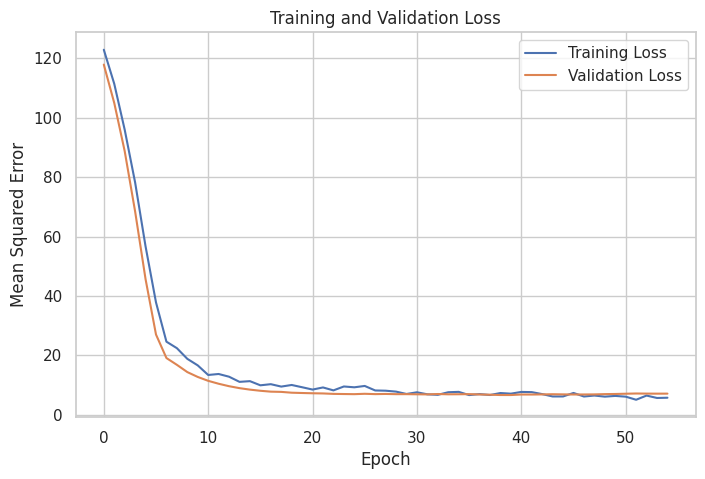

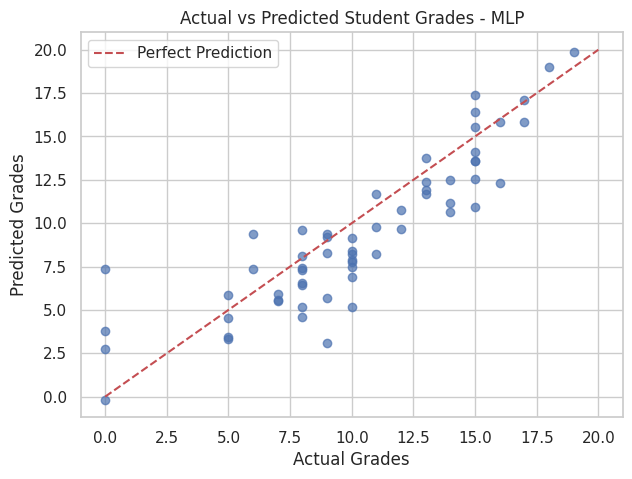

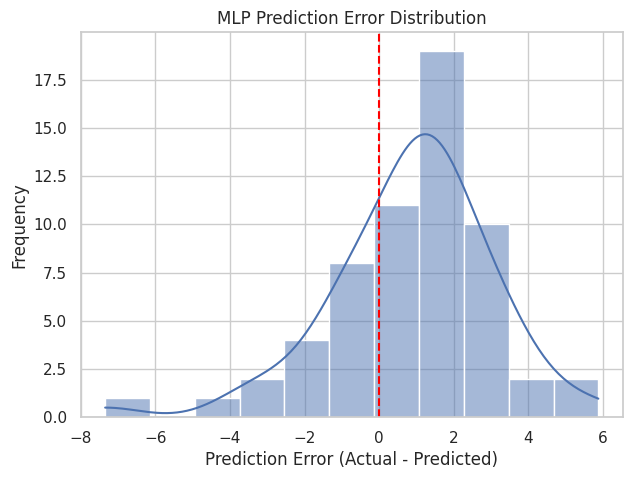

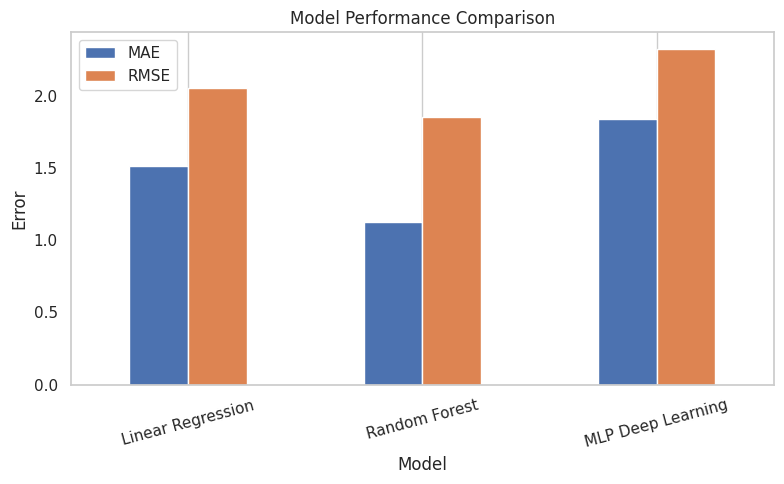

All four evaluation graphs saved successfully!


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os

os.makedirs("outputs/charts", exist_ok=True)
os.makedirs("outputs/results", exist_ok=True)

# 1. Predict using the trained MLP model
mlp_predictions = model.predict(X_test_proc, verbose=0).flatten()

# 2. Train baseline models for comparison
lr = LinearRegression()
lr.fit(X_train_proc, y_train)
lr_predictions = lr.predict(X_test_proc)

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train_proc, y_train)
rf_predictions = rf.predict(X_test_proc)

# 3. Calculate evaluation metrics
models_predictions = {
    "Linear Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "MLP Deep Learning": mlp_predictions
}

results = []

for name, predictions in models_predictions.items():
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
print("MODEL EVALUATION RESULTS")
display(results_df.round(4))

results_df.to_csv(
    "outputs/results/model_evaluation.csv",
    index=False
)

# 4. Visualization 1: Training and Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.savefig("outputs/charts/loss_curve.png", dpi=300)
plt.show()

# 5. Visualization 2: Actual vs Predicted Grades
plt.figure(figsize=(7, 5))
plt.scatter(y_test, mlp_predictions, alpha=0.7)
plt.plot([0, 20], [0, 20], "r--", label="Perfect Prediction")
plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Student Grades - MLP")
plt.legend()
plt.grid(True)
plt.savefig("outputs/charts/actual_vs_predicted.png", dpi=300)
plt.show()

# 6. Visualization 3: Prediction Error Distribution
residuals = y_test - mlp_predictions

plt.figure(figsize=(7, 5))
sns.histplot(residuals, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("MLP Prediction Error Distribution")
plt.savefig("outputs/charts/residual_distribution.png", dpi=300)
plt.show()

# 7. Visualization 4: Model Comparison
comparison = results_df.set_index("Model")[["MAE", "RMSE"]]

comparison.plot(kind="bar", figsize=(8, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.tight_layout()
plt.savefig("outputs/charts/model_comparison.png", dpi=300)
plt.show()

print("All four evaluation graphs saved successfully!")
